# VERSÃO COMPLETA DO FACILITADOR · Partes B a D com interpretação

O mesmo notebook dos estudantes, já executado com os **pontos da equipa** (`USAR_PONTOS_DA_EQUIPA = True`), com:
🔎 interpretação de cada resultado · 🗣️ o que dizer à turma · ⏱️ tempo · respostas-modelo.
Os números dos pares vão ser diferentes (cada par marca os seus pontos): o que importa é o padrão. **Não partilhar.**

# Partes B a D · A IA que encontra água (classificação supervisionada)

**Workshop de Estudantes 2 · Projecto EYES TO EARTH (ETE) · 21 de Novembro de 2026**

## A missão

> **Ensinar um computador a encontrar a água da cheia de janeiro de 2026 no Incomáti,
> testá-lo com honestidade e descobrir onde acerta e onde erra.**

É **aprendizagem supervisionada**: damos exemplos com a resposta certa (o **rótulo**). E é uma **classificação**:
para cada píxel, o modelo escolhe uma categoria, "água" ou "não água".

| Parte | O que fazemos | Tempo |
| --- | --- | --- |
| B | Marcar exemplos de "água" e "não água" no mapa (os **rótulos**) | 15 min |
| C | Treinar um **Random Forest**, fazer o **exame** e comparar quatro algoritmos | 20 min |
| D | Levar o modelo a **outro ano** e ensiná-lo com novos exemplos | 15 min |

Depois: `3_sem_rotulos_e_numeros.ipynb` (Partes E e F: agrupar sem rótulos e prever o caudal).


| Sinal | Quer dizer |
| --- | --- |
| ▶️ | Corra a célula: clique nela e prima **Shift + Enter** |
| ✏️ | Edite: troque os `...` pela sua resposta e corra outra vez |
| ✍️ | Responda por escrito, na célula de texto logo abaixo (duplo clique para escrever) |
| ✅ | A célula verifica a sua resposta |


**Como trabalhar no Jupyter Notebook:** clique numa célula e prima **Shift + Enter** para a correr (sempre por
ordem, de cima para baixo). Enquanto corre aparece `[*]` à esquerda; quando acaba, aparece um número. Para
escrever uma resposta, faça duplo clique na célula de texto. Guarde com **Ctrl + S**.

## As ferramentas (bibliotecas) que vamos usar

| Biblioteca | Para que serve | Comparação |
| --- | --- | --- |
| `numpy` (`np`) | Contas com tabelas de números. Uma imagem é uma tabela: cada píxel tem um número por banda | Calculadora gigante |
| `matplotlib` (`plt`) | Desenhar mapas e gráficos | Lápis de cor |
| `scikit-learn` (`sklearn`) | O Machine Learning: os modelos (`RandomForestClassifier` e outros) e as notas em `metrics` | A escola onde o modelo aprende e faz o exame |
| `json`, `os` | Ler a lista de pontos da equipa e encontrar os ficheiros | Abrir pastas |

**Os dados** (pasta `dados/`, cerca de 47 MB, preparados pela equipa ETE):
- `incomati_2026_cheia.npz` e `incomati_2026_seca.npz`: Sentinel-2, a 30 m, a 24 jan 2026 (cheia) e a 23 out 2025 (seca);
- `incomati_AAAA_chuvosa.npz`: os anos para o teste da Parte D (2014, 2021, 2022, 2024, 2025);
- `camadas_extra.npz`: o terreno e os **rótulos de teste** (do Copernicus EMS e do arquivo JRC);
- `exemplos_da_equipa.json`: pontos já marcados pela equipa, para quem precisar;
- `caudal_e_chuva_diarios.csv`: 20 anos de caudal e chuva, para a Parte F (no notebook 3).

## Célula 0 · Ligar as ferramentas ▶️

Corra sem mudar nada. Cria as "receitas" (funções) da aula: `carregar` abre uma imagem, `ver_imagem` e
`ver_zona` (a lupa) mostram-na, `exemplos` transforma pontos em exemplos, `prever` faz o mapa,
`notas` e `contar_erros` avaliam o modelo. Os dados estão na pasta `dados/`, ao lado deste notebook.

In [1]:
# Célula 0 · ferramentas da aula: corra sem mudar nada ▶️
import os                                   # os: encontrar ficheiros no computador
import json                                 # json: ler a lista de pontos da equipa
import numpy as np                          # numpy: contas com tabelas de números (uma imagem é uma tabela)
import matplotlib.pyplot as plt             # matplotlib: desenhar mapas e gráficos
from sklearn.ensemble import RandomForestClassifier   # scikit-learn: o modelo Random Forest
from sklearn import metrics                 # scikit-learn: as notas do modelo (acerto, IoU, F1, Kappa, ROC-AUC)

BANDAS = ["azul", "verde", "vermelho", "nir", "swir"]
INDICES = ["ndwi", "mndwi", "ndvi"]
TERRENO = ["hand", "altitude", "declive"]
RAIO = 2                                    # cada ponto marcado vale um quadrado de 5 x 5 píxeis (150 m x 150 m)


def encontrar(nome):
    """Procura um ficheiro de dados na pasta dados/ (ao lado do notebook, ou uma pasta acima)."""
    for pasta in ["dados", os.path.join("..", "dados"), "."]:
        caminho = os.path.join(pasta, nome)
        if os.path.exists(caminho):
            return caminho
    raise FileNotFoundError(f"Não encontrei {nome}. Abra o Jupyter na pasta Workshop_2/2_pratica: "
                            "os dados estão em 2_pratica/dados.")


def carregar(nome):
    """Abre uma imagem (.npz): as 5 bandas em reflectância (0 a 1) e os índices NDWI, MNDWI e NDVI."""
    z = np.load(encontrar(nome))
    img = {banda: z[banda] / 10000 for banda in BANDAS}
    with np.errstate(divide="ignore", invalid="ignore"):
        img["ndwi"] = (img["verde"] - img["nir"]) / (img["verde"] + img["nir"])
        img["mndwi"] = (img["verde"] - img["swir"]) / (img["verde"] + img["swir"])
        img["ndvi"] = (img["nir"] - img["vermelho"]) / (img["nir"] + img["vermelho"])
    img["nuvem"] = z["nuvem"]                   # True onde há nuvem, sombra ou falta de dados
    img["zona"] = z["zona"]                     # True dentro do distrito de Marracuene, fora do mar
    for chave in ["data", "satelite", "epoca"]:
        img[chave] = str(z[chave])
    img["caudal_m3s"] = float(z["caudal_m3s"])
    return img


def juntar_terreno(img, extra):
    """Acrescenta as camadas de terreno (iguais em todas as datas) às características da imagem."""
    for chave in TERRENO:
        img[chave] = extra[chave]
    return img


def cor_natural(img, brilho=0.15):
    """Junta vermelho, verde e azul numa imagem a cores."""
    return np.clip(np.dstack([img["vermelho"], img["verde"], img["azul"]]) / brilho, 0, 1)


def ver_imagem(img, titulo="", agua=(), nao_agua=(), grelha=100):
    """Mostra a imagem a cores com linhas e colunas numeradas, e os pontos marcados (círculo = água, quadrado = não água)."""
    plt.figure(figsize=(9, 12))
    plt.imshow(cor_natural(img))
    for linha, coluna in agua:
        plt.plot(coluna, linha, "o", ms=9, mfc="cyan", mec="black")
    for linha, coluna in nao_agua:
        plt.plot(coluna, linha, "s", ms=9, mfc="orange", mec="black")
    plt.xticks(range(0, img["verde"].shape[1], grelha))
    plt.yticks(range(0, img["verde"].shape[0], grelha))
    plt.grid(alpha=0.5, color="white")
    plt.xlabel("coluna")
    plt.ylabel("linha")
    plt.title(titulo)
    plt.show()


def ver_zona(img, linha, coluna, tamanho=60):
    """Lupa: mostra uma zona pequena à volta de (linha, coluna), com grelha fina, para escolher pontos certos."""
    l0, c0 = max(linha - tamanho, 0), max(coluna - tamanho, 0)
    recorte = cor_natural(img)[l0:linha + tamanho, c0:coluna + tamanho]
    plt.figure(figsize=(7, 7))
    plt.imshow(recorte, extent=(c0 - 0.5, c0 + recorte.shape[1] - 0.5, l0 + recorte.shape[0] - 0.5, l0 - 0.5))
    plt.plot(coluna, linha, "+", ms=20, color="red")
    plt.grid(alpha=0.5, color="white")
    plt.xlabel("coluna")
    plt.ylabel("linha")
    plt.title(f"Lupa à volta da linha {linha}, coluna {coluna}")
    plt.show()


def tabela(img, caracteristicas):
    """Uma linha por píxel e uma coluna por característica: é assim que o modelo lê a imagem."""
    pilha = np.stack([img[c] for c in caracteristicas], axis=-1)
    return np.nan_to_num(pilha.reshape(-1, len(caracteristicas)))


def exemplos(img, agua, nao_agua, caracteristicas, raio=RAIO, grupos=False):
    """Transforma os pontos marcados em exemplos: X (as características) e y (1 = água, 0 = não água).
    raio: cada ponto vale um quadrado de (2 x raio + 1)² píxeis. grupos=True devolve também o número do ponto
    de cada píxel (para a validação cruzada por pontos, no nível avançado)."""
    pilha = np.nan_to_num(np.stack([img[c] for c in caracteristicas], axis=-1))
    X, y, g, nas_nuvens = [], [], [], 0
    for classe, pontos in ((1, agua), (0, nao_agua)):
        for linha, coluna in pontos:
            janela = (slice(max(linha - raio, 0), linha + raio + 1), slice(max(coluna - raio, 0), coluna + raio + 1))
            limpo = ~img["nuvem"][janela]
            if not limpo.any():
                nas_nuvens += 1
                continue
            X.append(pilha[janela][limpo])
            y.append(np.full(limpo.sum(), classe))
            g.append(np.full(limpo.sum(), len(g)))
    if nas_nuvens:
        print(f"Atenção: {nas_nuvens} ponto(s) caíram em nuvens ou fora da imagem e foram ignorados.")
    if grupos:
        return np.concatenate(X), np.concatenate(y), np.concatenate(g)
    return np.concatenate(X), np.concatenate(y)


def prever(modelo, img, caracteristicas):
    """A probabilidade de ser água (0 a 1), para cada píxel da imagem."""
    probabilidade = modelo.predict_proba(tabela(img, caracteristicas))[:, 1]
    return probabilidade.reshape(img["verde"].shape)


def notas(verdade, previsto, probabilidade=None):
    """As notas do modelo comparado com a verdade (1 = água, 0 = não água)."""
    r = {"acerto": metrics.accuracy_score(verdade, previsto),
         "IoU": metrics.jaccard_score(verdade, previsto),
         "F1": metrics.f1_score(verdade, previsto),
         "Kappa": metrics.cohen_kappa_score(verdade, previsto)}
    if probabilidade is not None:
        r["ROC-AUC"] = metrics.roc_auc_score(verdade, probabilidade)
    return r


def mostrar_notas(nome, r):
    print(f"{nome:28s}", "  ".join(f"{k} {v:.3f}" for k, v in r.items()))


def contar_erros(verdade, previsto):
    """A matriz de confusão em palavras: o que acertou e o que errou."""
    agua_certa = int(((verdade == 1) & (previsto == 1)).sum())
    terra_certa = int(((verdade == 0) & (previsto == 0)).sum())
    falso_alarme = int(((verdade == 0) & (previsto == 1)).sum())
    agua_perdida = int(((verdade == 1) & (previsto == 0)).sum())
    print(f"Água que o modelo encontrou (certo):      {agua_certa:8d} píxeis")
    print(f"Terra que o modelo disse terra (certo):   {terra_certa:8d} píxeis")
    print(f"Falsos alarmes (terra que disse água):    {falso_alarme:8d} píxeis")
    print(f"Água perdida (água que disse terra):      {agua_perdida:8d} píxeis")
    return agua_certa, terra_certa, falso_alarme, agua_perdida


print("Ferramentas prontas.")

Ferramentas prontas.


## ⚙️ Painel de configuração ▶️

Todas as escolhas do modelo estão **aqui, num só sítio**. Na primeira vez, corra sem mudar nada. Depois, para
experimentar, mude um valor, corra esta célula e volte a correr as células da parte que quer ver (por exemplo, a Parte C).

Os números que mudam o comportamento de um modelo chamam-se **hiperparâmetros**: são os "botões" do modelo.
Não são aprendidos com os exemplos: somos nós que os escolhemos (e, no nível avançado, que os afinamos com o computador).

In [2]:
# ⚙️ PAINEL DE CONFIGURAÇÃO: mude os valores aqui e volte a correr as células da parte que quer ver
CONFIG = {
    # os exemplos (Parte B)
    "raio_do_ponto": 2,                      # cada ponto vale um quadrado de (2 x raio + 1)² píxeis: 2 dá 5 x 5
    "caracteristicas": BANDAS + INDICES,     # as pistas: BANDAS, INDICES e, se quiserem, TERRENO
    # o Random Forest (Parte C): os hiperparâmetros
    "n_arvores": 100,                        # quantas árvores votam (experimente 10 ou 300)
    "profundidade_maxima": None,             # None = sem limite; experimente 2 ou 5
    "folhas_minimas": 1,                     # mínimo de píxeis em cada folha (mais = modelo mais simples)
    "pistas_por_pergunta": "sqrt",           # quantas pistas cada pergunta pode escolher ("sqrt" = raiz do total)
    "pesos_das_classes": None,               # None = cada píxel conta igual; "balanced" = água e terra pesam o mesmo
    # a decisão
    "limiar": 0.5,                           # acima desta probabilidade dizemos "água" (experimente 0.3 ou 0.7)
    "semente": 0,                            # o mesmo número dá sempre o mesmo resultado
}
print("Configuração pronta:", ", ".join(f"{chave} = {valor}" for chave, valor in CONFIG.items() if chave != "caracteristicas"))

Configuração pronta: raio_do_ponto = 2, n_arvores = 100, profundidade_maxima = None, folhas_minimas = 1, pistas_por_pergunta = sqrt, pesos_das_classes = None, limiar = 0.5, semente = 0


🔎 **Como usar o painel.** Na prática, os pares correm-no sem mudar nada (são os valores dos resultados de referência). Para os pares
rápidos, depois da Parte C: `"n_arvores": 10` ou `300` (quase não muda nesta imagem fácil); `"profundidade_maxima": 2` (a floresta
fica mais simples e erra mais nas bordas); `"limiar": 0.3` (mais água encontrada, mais falsos alarmes) ou `0.7` (o contrário);
`"caracteristicas": BANDAS + INDICES + TERRENO` (junta o terreno). Depois de mudar, corram outra vez o painel e as células da Parte C.

🗣️ **Dizer à turma:** "Os hiperparâmetros são os botões do modelo. O modelo aprende com os exemplos; os botões somos nós que os escolhemos."

---
# Parte B · Marcar exemplos: os rótulos (15 min)

Um modelo aprende com **exemplos com a resposta certa**: os **rótulos**. Aqui, cada rótulo é um ponto que
**vocês** marcam na imagem e dizem: "isto é água" ou "isto não é água".

Cada ponto é uma **morada**: `(linha, coluna)`, como na batalha naval. Cada ponto vale um quadradinho de
5 × 5 píxeis (150 m × 150 m), ou seja, até 25 exemplos.

### Passo B1 · Abrir as imagens ▶️

In [3]:
cheia = carregar("incomati_2026_cheia.npz")
seca = carregar("incomati_2026_seca.npz")
extra = dict(np.load(encontrar("camadas_extra.npz")))
for img in (cheia, seca):
    juntar_terreno(img, extra)                     # o terreno fica disponível como pista (ver o painel ⚙️)

print("Cheia:", cheia["data"], cheia["satelite"], f"caudal {cheia['caudal_m3s']:.0f} m³/s")
print("Seca: ", seca["data"], seca["satelite"], f"caudal {seca['caudal_m3s']:.1f} m³/s")
print("Tamanho:", cheia["verde"].shape, "píxeis de 30 m x 30 m")

Cheia: 2026-01-24 Sentinel-2 caudal 1693 m³/s
Seca:  2025-10-23 Sentinel-2 caudal 5.4 m³/s
Tamanho: (1110, 735) píxeis de 30 m x 30 m


🔎 **Interpretação.** A imagem da cheia é de 24 jan 2026 (Sentinel-2, 1 693 m³/s, 5 dias depois do pico de 2 987 m³/s) e a da
seca de 23 out 2025 (5,4 m³/s). Cada uma tem 1 110 × 735 = 815 850 píxeis de 30 m.

⏱️ **Tempo:** Parte B entre as 11:55 e as 12:10.

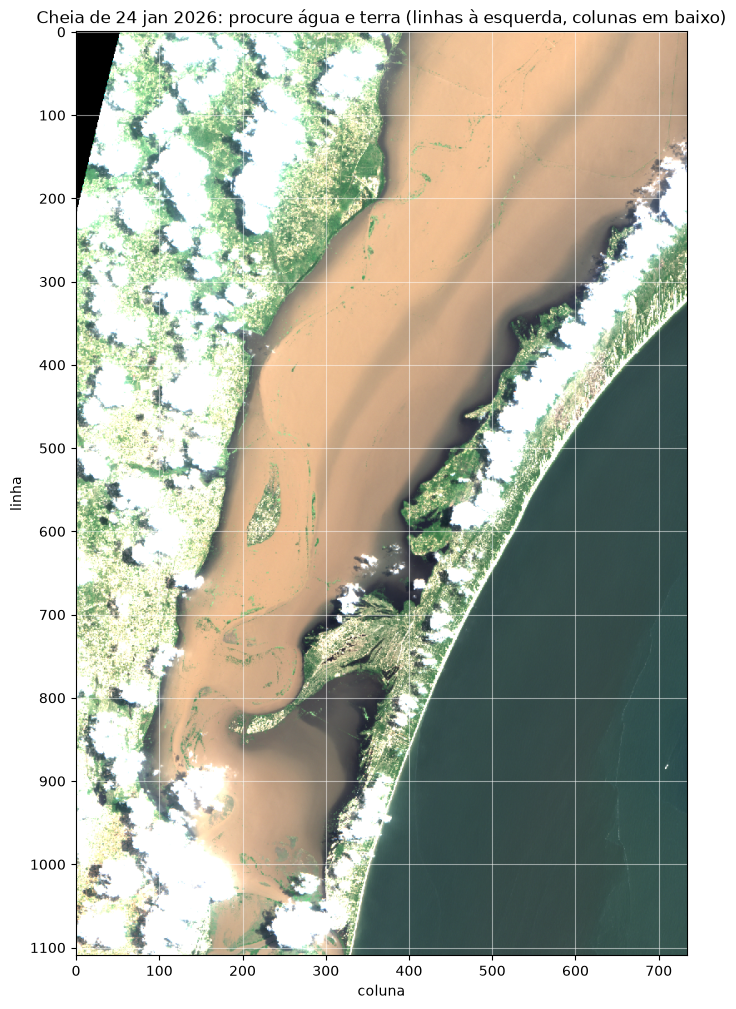

In [4]:
ver_imagem(cheia, "Cheia de 24 jan 2026: procure água e terra (linhas à esquerda, colunas em baixo)")

### Passo B2 · A lupa ✏️

Para escolher um ponto com precisão, use a lupa: troque a linha e a coluna e corra.
A cruz vermelha marca o centro. **Não escolha pontos em cima de nuvens (branco) nem na borda entre água e terra.**

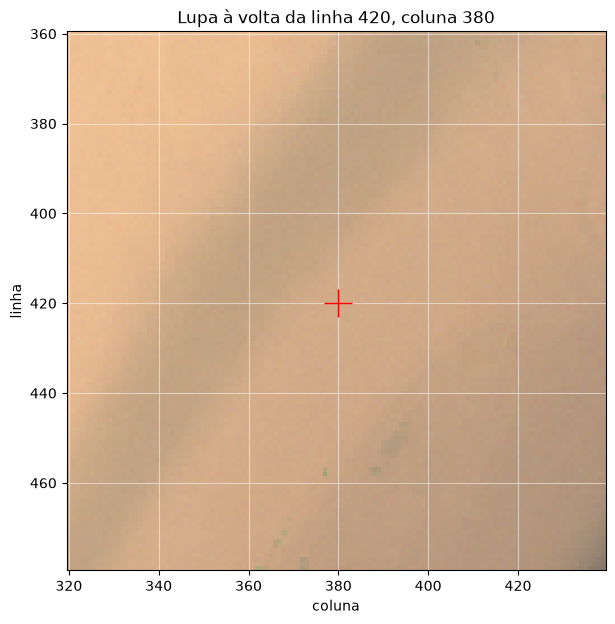

In [5]:
ver_zona(cheia, linha=420, coluna=380)        # ✏️ troque os números e corra outra vez

🔎 **Como usar.** A lupa mostra 120 × 120 píxeis à volta do ponto. Os estudantes lêem a linha e a coluna dos eixos.
🗣️ **Dizer à turma:** "É como a batalha naval: primeiro a linha (de cima para baixo), depois a coluna (da esquerda para a direita)."

### Passo B3 · Marcar os vossos pontos ✏️

Marquem **pelo menos 10 pontos de água e 10 de não água**, com **variedade**:

| Água | Não água |
| --- | --- |
| água castanha da cheia | vegetação (verde escuro) |
| o leito do rio | campos e mato |
| lagoas de água escura | areia e solo claro (dunas, terra nua) |
| | a vila (telhados, estradas) |

Já lá estão 3 pontos certos de cada, para começar. Se o tempo apertar, ponham `USAR_PONTOS_DA_EQUIPA = True`
para usar os 15 + 15 pontos que a equipa marcou.

15 pontos de água e 15 pontos de não água


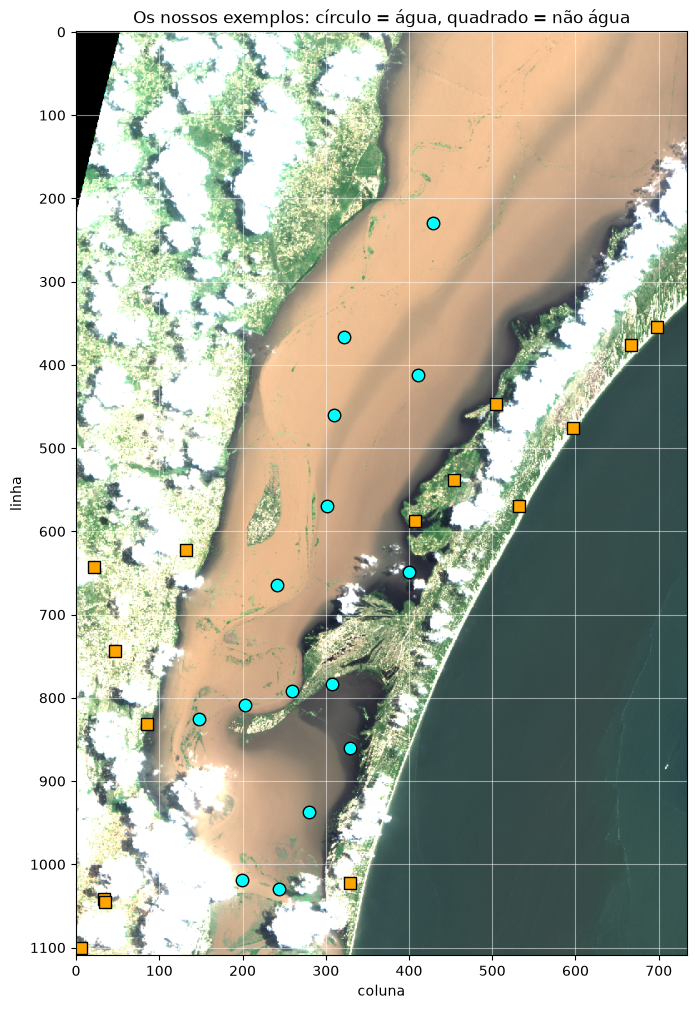

Pontos guardados em os_nossos_pontos.json


In [6]:
USAR_PONTOS_DA_EQUIPA = True        # ✏️ True para usar os 15 + 15 pontos da equipa ETE

AGUA = [(366, 322), (937, 280), (412, 411)]           # ✏️ acrescente os seus pontos de água (linha, coluna)
NAO_AGUA = [(832, 85), (538, 454), (376, 667)]       # ✏️ acrescente os seus pontos de não água

if USAR_PONTOS_DA_EQUIPA:
    equipa = json.load(open(encontrar("exemplos_da_equipa.json")))
    AGUA = [tuple(p) for p in equipa["2026"]["agua"]]
    NAO_AGUA = [tuple(p) for p in equipa["2026"]["nao_agua"]]

print(len(AGUA), "pontos de água e", len(NAO_AGUA), "pontos de não água")
if min(len(AGUA), len(NAO_AGUA)) < 10:
    print("✏️ Ainda poucos: marquem pelo menos 10 de cada (ou usem os pontos da equipa).")
ver_imagem(cheia, "Os nossos exemplos: círculo = água, quadrado = não água", AGUA, NAO_AGUA)

with open("os_nossos_pontos.json", "w") as ficheiro:      # guardar os pontos: o nível avançado e os scripts usam-nos
    json.dump({"agua": [list(p) for p in AGUA], "nao_agua": [list(p) for p in NAO_AGUA]}, ficheiro)
print("Pontos guardados em os_nossos_pontos.json")

🔎 **Interpretação.** Com `USAR_PONTOS_DA_EQUIPA = True` aparecem os 15 + 15 pontos da equipa: água da
cheia, o rio e lagoas escuras; vegetação, campos, areia e a zona da vila. Um par lento deve usá-los às 12:05, para não atrasar a turma.

🗣️ **Resposta-modelo à pergunta:** porque o modelo só aprende o que vê. Se só lhe mostrarmos água castanha, pode não reconhecer
água escura (como em 2024) ou água limpa.

✍️ **Pergunta:** porque é importante marcar água de **vários tipos** (barrenta, rio, lagoa escura) e não
apenas a água castanha da cheia?

**Resposta-modelo:** Porque o modelo só reconhece o que viu nos exemplos. Água castanha, água do rio e água escura têm valores diferentes; se faltar um tipo, o modelo pode falhar nesse tipo (foi o que aconteceu à regra MNDWI em 2024).

---
# Parte C · Treinar e avaliar o modelo (20 min)

### Passo C1 · As características ✏️

Para cada píxel, o modelo recebe uma lista de **características** (as pistas): as 5 bandas do satélite e
3 índices (NDWI e MNDWI para a água, NDVI para a vegetação). Para tirar ou pôr características, mude
`"caracteristicas"` no painel ⚙️ (por exemplo, só `BANDAS`, ou `["nir", "swir"]`).

In [7]:
CARACTERISTICAS = CONFIG["caracteristicas"]       # ✏️ para mudar as pistas, altere o painel ⚙️
print("Características:", CARACTERISTICAS)

X, y = exemplos(cheia, AGUA, NAO_AGUA, CARACTERISTICAS, raio=CONFIG["raio_do_ponto"])
print(f"Exemplos para aprender: {len(y)} píxeis ({y.sum()} de água e {len(y) - y.sum()} de não água)")
print("O primeiro exemplo (uma linha da tabela):", np.round(X[0], 3), "-> rótulo", y[0])

Características: ['azul', 'verde', 'vermelho', 'nir', 'swir', 'ndwi', 'mndwi', 'ndvi']
Exemplos para aprender: 738 píxeis (375 de água e 363 de não água)
O primeiro exemplo (uma linha da tabela): [ 0.087  0.112  0.14   0.066  0.011  0.261  0.821 -0.361] -> rótulo 1


🔎 **Interpretação.** Com os pontos da equipa há 738 píxeis de treino (375 de água). Cada píxel é uma
linha com 8 números. Os pontos dos pares darão números parecidos (entre 400 e 800 píxeis).

⏱️ **Tempo:** Parte C entre as 12:10 e as 12:30.

`X` é a tabela das características (uma linha por píxel) e `y` são os rótulos (1 = água, 0 = não água).
É exactamente o que vimos na Parte A, mas com centenas de píxeis.

### Passo C2 · Aprender ▶️

O modelo é criado com os hiperparâmetros do painel ⚙️ e `fit(X, y)` é o momento em que **aprende**.

In [8]:
modelo = RandomForestClassifier(
    n_estimators=CONFIG["n_arvores"],              # quantas árvores votam
    max_depth=CONFIG["profundidade_maxima"],       # quantas perguntas seguidas, no máximo (None = sem limite)
    min_samples_leaf=CONFIG["folhas_minimas"],     # quantos píxeis, no mínimo, em cada folha
    max_features=CONFIG["pistas_por_pergunta"],    # quantas pistas cada pergunta pode escolher
    class_weight=CONFIG["pesos_das_classes"],      # o peso da água e da terra
    random_state=CONFIG["semente"], n_jobs=-1)     # n_jobs=-1: usa todos os processadores
modelo.fit(X, y)                                   # APRENDER
print(f"O modelo aprendeu com {len(y)} píxeis e {CONFIG['n_arvores']} árvores.")

O modelo aprendeu com 738 píxeis e 100 árvores.


🔎 **Interpretação.** O treino demora menos de 1 segundo: é por isso que o Random Forest é óptimo para aprender.
🗣️ **Dizer à turma:** "`fit` é o momento em que a máquina aprende. Foi rápido porque os exemplos são poucos e claros."

### Passo C3 · O mapa do modelo ▶️

Agora o modelo olha para **todos os 815 850 píxeis** da imagem e dá a cada um a **probabilidade de ser água**
(a parte das árvores que votou "água"). Acima de 0,5 dizemos "água".

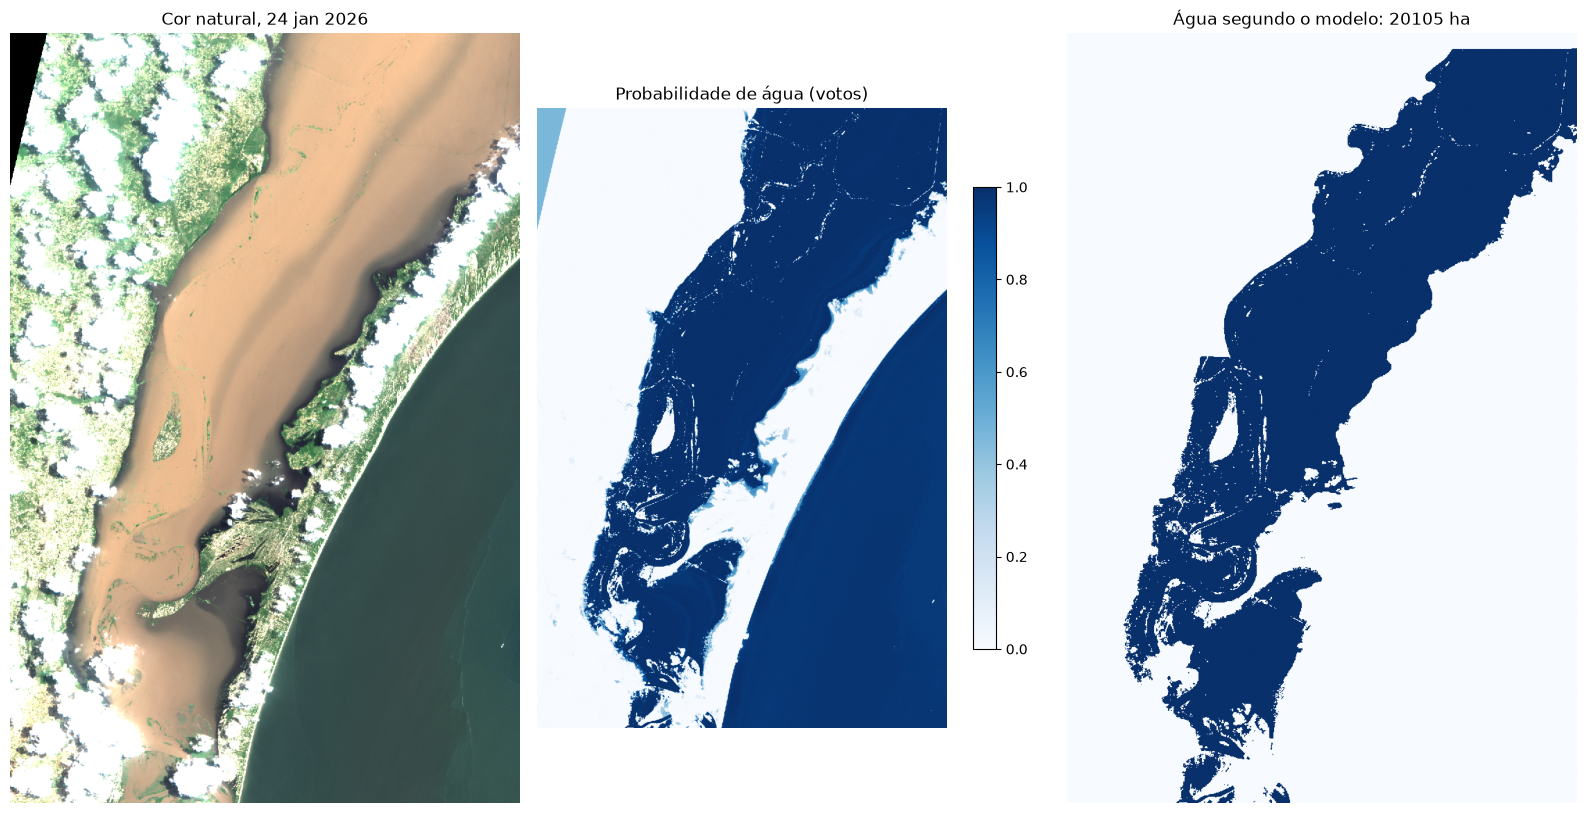

In [9]:
probabilidade = prever(modelo, cheia, CARACTERISTICAS)
agua_modelo = (probabilidade > CONFIG["limiar"]) & cheia["zona"] & ~cheia["nuvem"]

fig, eixos = plt.subplots(1, 3, figsize=(16, 8))
eixos[0].imshow(cor_natural(cheia))
eixos[0].set_title("Cor natural, 24 jan 2026")
figura = eixos[1].imshow(probabilidade, cmap="Blues", vmin=0, vmax=1)
eixos[1].set_title("Probabilidade de água (votos)")
fig.colorbar(figura, ax=eixos[1], shrink=0.6)
eixos[2].imshow(agua_modelo, cmap="Blues")
eixos[2].set_title(f"Água segundo o modelo: {agua_modelo.sum() * 0.09:.0f} ha")
for e in eixos:
    e.axis("off")
plt.tight_layout()
plt.show()

🔎 **Interpretação.** O mapa de probabilidade é quase só 0 (terra) ou 1 (água): as árvores concordam quase sempre. Os tons
intermédios ficam nas bordas e em zonas de água pouco funda. Com os pontos da equipa, o modelo encontra cerca de
20 105 ha de água na zona visível (no Workshop 1, a regra MNDWI deu 21 248 ha).

### Passo C4 · O que o modelo achou mais importante ▶️

O Random Forest diz que características usou mais para decidir (a **importância**). As importâncias somam 1.

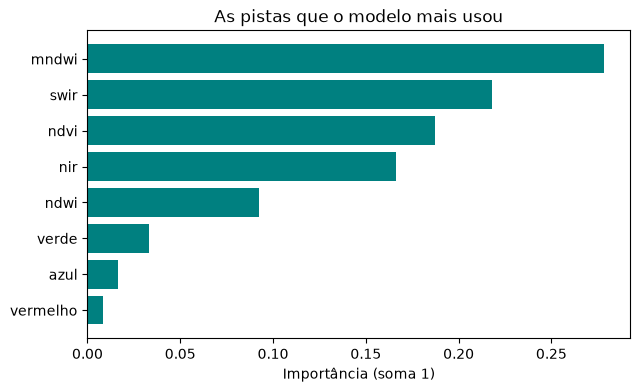

In [10]:
ordem = np.argsort(modelo.feature_importances_)
plt.figure(figsize=(7, 4))
plt.barh(np.array(CARACTERISTICAS)[ordem], modelo.feature_importances_[ordem], color="teal")
plt.xlabel("Importância (soma 1)")
plt.title("As pistas que o modelo mais usou")
plt.show()

🔎 **Interpretação.** Com os pontos da equipa, as pistas mais usadas foram: mndwi (0,28), swir (0,22), ndvi (0,19), nir (0,17). O azul e o verde
quase não contam. O MNDWI e o SWIR lideram porque a água absorve quase todo o SWIR.

🗣️ **Resposta-modelo:** a água absorve o infravermelho (NIR e SWIR) e por isso fica escura nessas bandas; a terra e as plantas reflectem-no.

✍️ **Perguntas:** que características o modelo mais usou? Porque é que o NIR e o SWIR ajudam tanto a encontrar
água? (Pista: Workshop 1, a água absorve o infravermelho.)

**Resposta-modelo:** Com os pontos da equipa: MNDWI, SWIR, NDVI e NIR. A água absorve o infravermelho (NIR e SWIR), por isso fica muito escura nessas bandas, ao contrário da terra e das plantas.

### Passo C5 · A nota "batoteira" ▶️

Primeiro, a pergunta errada: o modelo acerta nos **próprios exemplos** que estudou?

In [11]:
acerto_treino = (modelo.predict(X) == y).mean()
print(f"Acerto nos exemplos de treino: {100 * acerto_treino:.1f}%")

Acerto nos exemplos de treino: 100.0%


🔎 **Interpretação.** 100,0% nos exemplos de treino. E se dividíssemos os mesmos píxeis ao acaso em treino e teste,
também daria 100,0%: píxeis vizinhos do mesmo ponto são quase iguais, por isso é como copiar.

🗣️ **Dizer à turma:** "Um estudante que decora as respostas tira 20 no teste que já viu. O exame a sério é com perguntas novas."

Quase 100%! Mas isto é como dar a um estudante o exame com as perguntas que ele já estudou: **não prova
nada**. Um bom modelo tem de acertar em casos que **nunca viu**.

### Passo C6 · O exame: testar com rótulos independentes ▶️

> **Regra de ouro:** testa-se sempre com dados que o modelo **nunca viu** e com rótulos que **não foram
> feitos pelo próprio modelo**.

O nosso "exame" são as amostras de água e não água do **Copernicus EMS** (EMSR857): mapas da cheia de
janeiro de 2026 feitos por especialistas europeus, com outras imagens. O modelo nunca as viu.

(O EMS marca só a água **da cheia**, não o rio de sempre. A equipa juntou ao exame o leito normal do rio,
tirado do arquivo de 38 anos de água do satélite Landsat, o JRC. Até um exame pode ter erros!)

Píxeis no exame: 339409 (251954 de água e 87455 de não água)

Água que o modelo encontrou (certo):        242297 píxeis
Terra que o modelo disse terra (certo):      87426 píxeis
Falsos alarmes (terra que disse água):          29 píxeis
Água perdida (água que disse terra):          9657 píxeis

O nosso modelo               acerto 0.971  IoU 0.962  F1 0.980  Kappa 0.928  ROC-AUC 0.995


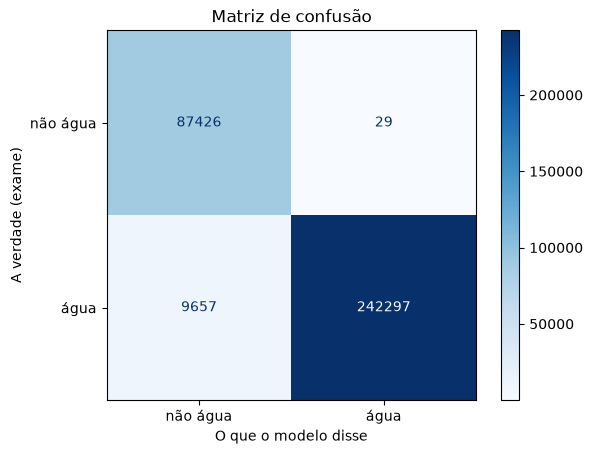

In [12]:
ems = extra["ems_2026"]                              # 1 água, 0 não água, -1 sem rótulo
teste = (ems >= 0) & ~cheia["nuvem"]                 # só onde há rótulo e não há nuvem
verdade = ems[teste]
previsto = (probabilidade[teste] > CONFIG["limiar"]).astype(int)
print(f"Píxeis no exame: {teste.sum()} ({verdade.sum()} de água e {(verdade == 0).sum()} de não água)\n")
contar_erros(verdade, previsto)
print()
mostrar_notas("O nosso modelo", notas(verdade, previsto, probabilidade[teste]))

# a matriz de confusão: as mesmas quatro contas, numa tabela de 2 x 2
metrics.ConfusionMatrixDisplay.from_predictions(verdade, previsto, display_labels=["não água", "água"], cmap="Blues",
                                                values_format="d")
plt.xlabel("O que o modelo disse")
plt.ylabel("A verdade (exame)")
plt.title("Matriz de confusão")
plt.show()

🔎 **Interpretação (pontos da equipa).** O exame tem 339 409 píxeis (251 954 de água). O modelo encontrou
242 297 píxeis de água certos e 87 426 de terra certos; errou 29 falsos alarmes e
9 657 píxeis de água perdida. Notas: acerto 0,971, IoU 0,962, F1 0,980,
Kappa 0,928, ROC-AUC 0,995.

Nota técnica: o EMS mapeia só a água da cheia; as suas amostras "não água" caíam em cima do leito normal do rio. A equipa passou
4 419 desses píxeis a "água" (arquivo JRC: água em 50% ou mais das observações de 1984 a 2021). Sem esta
correcção, quase todos os "falsos alarmes" do modelo (2 883 de 2 901) estavam no rio: o modelo tinha razão e o exame não.

🗣️ **Dizer à turma:** "Desceu de 100% para 97%: esta é a nota verdadeira. E 97% num exame
que nunca viu é muito bom."

A **matriz de confusão** mostra as mesmas quatro contas numa tabela 2 × 2: na diagonal os acertos (água certa e terra certa),
fora da diagonal os erros (falso alarme e água perdida). É o mesmo quadro do slide da teoria.

### As notas, em palavras simples

| Nota | O que mede | Como ler |
| --- | --- | --- |
| **Acerto** | Parte dos píxeis classificados bem | 0,96 = 96 em cada 100 certos. Engana quando há muito mais terra do que água |
| **IoU** | Sobreposição entre a água prevista e a água verdadeira (intersecção ÷ união) | 1 = os dois mapas de água coincidem; 0 = não se tocam |
| **F1** | Equilíbrio entre não dar falsos alarmes e não perder água | Perto de 1 = bom nas duas coisas |
| **Kappa** | Acerto **acima do que se teria por sorte** | 0 = como atirar uma moeda; acima de 0,8 = muito bom |
| **ROC-AUC** | Se o modelo dá notas mais altas à água do que à terra | 0,5 = ao calhas; 1 = ordena tudo bem |

### Passo C7 · O mapa dos erros ▶️

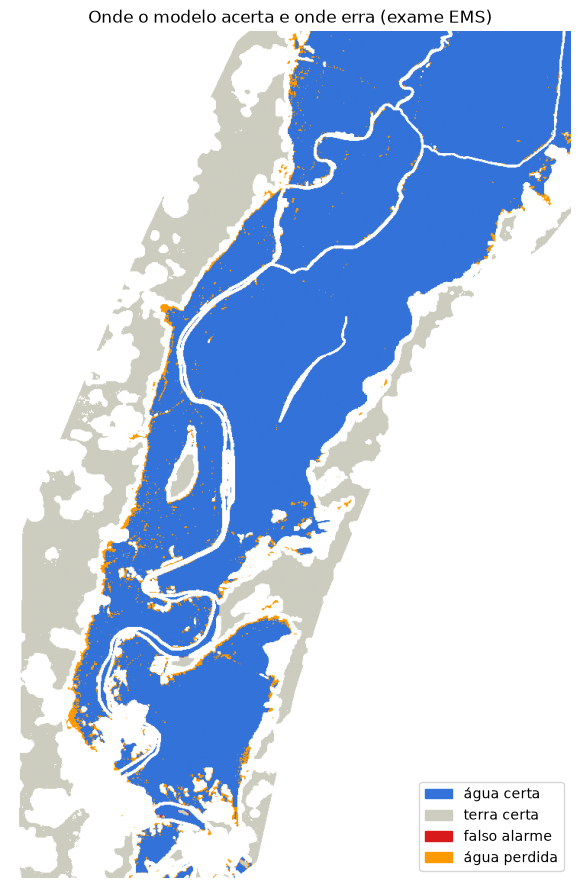

In [13]:
mapa_erros = np.ones(cheia["verde"].shape + (3,))                        # fundo branco
verdade_mapa, previsto_mapa = ems, (probabilidade > CONFIG["limiar"])
mapa_erros[teste & (verdade_mapa == 1) & previsto_mapa] = [0.20, 0.45, 0.85]     # água certa: azul
mapa_erros[teste & (verdade_mapa == 0) & ~previsto_mapa] = [0.80, 0.80, 0.75]    # terra certa: cinzento
mapa_erros[teste & (verdade_mapa == 0) & previsto_mapa] = [0.85, 0.10, 0.10]     # falso alarme: vermelho
mapa_erros[teste & (verdade_mapa == 1) & ~previsto_mapa] = [1.00, 0.60, 0.00]    # água perdida: laranja

from matplotlib.patches import Patch
plt.figure(figsize=(8, 11))
plt.imshow(mapa_erros)
plt.legend(handles=[Patch(color=[0.20, 0.45, 0.85], label="água certa"), Patch(color=[0.80, 0.80, 0.75], label="terra certa"),
                    Patch(color=[0.85, 0.10, 0.10], label="falso alarme"), Patch(color=[1.00, 0.60, 0.00], label="água perdida")],
           loc="lower right")
plt.title("Onde o modelo acerta e onde erra (exame EMS)")
plt.axis("off")
plt.show()

🔎 **Interpretação.** A maior parte é azul (água certa) e cinzenta (terra certa). Quase não há falsos alarmes (29 píxeis a
vermelho). O erro que conta é a **água perdida** (laranja, 9 657 píxeis): nas **bordas** da cheia, água pouco funda
ou entre vegetação, que o modelo confunde com terra.

🗣️ **Resposta-modelo:** nas bordas, um píxel de 30 m tem metade água e metade terra (píxel misto), e a água é pouco funda ou está
entre plantas.

✍️ **Pergunta:** onde ficam os erros: no meio da cheia ou nas bordas? Porque é que as bordas são difíceis?

**Resposta-modelo:** Sobretudo nas bordas da cheia: os píxeis de 30 m misturam água e terra, a água é pouco funda ou está entre plantas. No meio da cheia quase não há erros.

### Passo C8 · Quatro algoritmos, os mesmos exemplos, o mesmo exame ▶️

Na teoria vimos quatro algoritmos de classificação. Todos aprendem com **os mesmos exemplos** (`X`, `y`) e
fazem **o mesmo exame**. E juntamos as regras do Workshop 1 (MNDWI > 0 e NDWI > 0). Quem ganha?

In [14]:
from sklearn.tree import DecisionTreeClassifier          # árvore de decisão: perguntas de sim ou não
from sklearn.neighbors import KNeighborsClassifier       # k vizinhos mais próximos: "diz-me com quem andas"
from sklearn.neural_network import MLPClassifier         # rede neuronal (a ideia do Deep Learning)
from sklearn.pipeline import make_pipeline               # encadear dois passos num só modelo
from sklearn.preprocessing import StandardScaler         # pôr todas as características na mesma escala

ALGORITMOS = {
    "Árvore de decisão": DecisionTreeClassifier(random_state=0),
    "k vizinhos (k = 5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    f"Random Forest ({CONFIG['n_arvores']} árvores)": modelo,      # o nosso, já treinado no Passo C2
    "Rede neuronal (16 + 16)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16, 16),
                                                                            max_iter=800, random_state=0)),
}
for nome, m in ALGORITMOS.items():
    if m is not modelo:
        m.fit(X, y)                                          # cada um aprende com os MESMOS exemplos
    p = prever(m, cheia, CARACTERISTICAS)
    mostrar_notas(nome, notas(verdade, (p[teste] > CONFIG["limiar"]).astype(int)))
mostrar_notas("Regra MNDWI > 0 (Workshop 1)", notas(verdade, (cheia["mndwi"][teste] > 0).astype(int)))
mostrar_notas("Regra NDWI > 0 (Workshop 1)", notas(verdade, (cheia["ndwi"][teste] > 0).astype(int)))
r = notas(verdade, previsto)
print(f"\nQUADRO DA TURMA -> pontos {len(AGUA)}+{len(NAO_AGUA)} | IoU {r['IoU']:.3f} | acerto {r['acerto']:.3f} | Kappa {r['Kappa']:.3f}")

Árvore de decisão            acerto 0.975  IoU 0.966  F1 0.983  Kappa 0.936


k vizinhos (k = 5)           acerto 0.984  IoU 0.979  F1 0.989  Kappa 0.960


Random Forest (100 árvores)  acerto 0.971  IoU 0.962  F1 0.980  Kappa 0.928


Rede neuronal (16 + 16)      acerto 0.981  IoU 0.974  F1 0.987  Kappa 0.951
Regra MNDWI > 0 (Workshop 1) acerto 0.992  IoU 0.989  F1 0.995  Kappa 0.980


Regra NDWI > 0 (Workshop 1)  acerto 0.977  IoU 0.969  F1 0.984  Kappa 0.942

QUADRO DA TURMA -> pontos 15+15 | IoU 0.962 | acerto 0.971 | Kappa 0.928


🔎 **Interpretação (pontos da equipa).** No exame de 2026:

| Algoritmo | IoU no exame 2026 | Rio encontrado em 2021 | Rio encontrado em 2024 |
| --- | --- | --- | --- |
| Árvore de decisão | 0,966 | 58% | 97% |
| k vizinhos (k = 5) | 0,979 | 58% | 97% |
| Random Forest (100 árvores) | 0,962 | 46% | 96% |
| Rede neuronal (16 + 16) | 0,974 | 55% | 0% |
| Regra MNDWI > 0 | 0,989 | 77% | 0% |

Nesta imagem fácil todos empatam, perto de 0,96 a 0,98, e a regra MNDWI é até um pouco melhor. A diferença está nos outros
anos (Parte D): a **rede neuronal**, que no exame de 2026 fica à frente do Random Forest, **não encontra o rio de 2024**
(água muito escura): com poucos exemplos, aprendeu uma regra frágil. É a lição da teoria: a nota num exame fácil não prova
que o modelo funciona em todo o lado.

🗣️ **Resposta-modelo:** nesta imagem não há um vencedor claro; a IA serve para os casos em que a regra falha e para juntar
muitas pistas sem as escrevermos à mão. O vencedor de hoje pode perder noutro ano (Parte D).

✍️ **Pergunta:** qual ganhou no exame de 2026? A IA é muito melhor do que a regra MNDWI nesta imagem? Será que o
vencedor de hoje também ganha **noutro ano**? (A Parte D responde.)

**Resposta-modelo:** Com os pontos da equipa, os k vizinhos (IoU 0,979) e a rede neuronal ficam um pouco à frente do Random Forest (0,962), e a regra MNDWI tem 0,989: nesta imagem limpa todos empatam. O vencedor não ganha necessariamente noutro ano: em 2024 a rede neuronal não encontra o rio (Parte D).

---
# Parte D · Será que o modelo funciona noutro ano? (15 min)

Uma regra fixa pode falhar quando a água muda de aspecto: no Workshop 1, o NDWI falhou com a **água barrenta**
de 2021 e o MNDWI falhou com a **água muito escura** de 2024. E o nosso modelo, que só viu 2026?

| Par | Ano |
| --- | --- |
| Par 1 | 2024 |
| Par 2 | 2021 |
| Par 3 | 2022 |
| Par 4 | 2014 |
| Par 5 | 2025 |

Nesses anos não há mapas do EMS. Usamos dois rótulos de verificação que **não vêm do modelo**:
- **rio certo**: onde o arquivo JRC (1984–2021) viu água em 90% ou mais das vezes;
- **terra alta**: terreno a 10 m ou mais acima do rio, onde o JRC nunca viu água (nunca alaga).

### Passo D1 · Aplicar o modelo ao vosso ano ✏️

2024-01-20 Sentinel-2 caudal 240 m³/s



O nosso modelo:   encontra  96.4% do rio certo | falsos alarmes em terra alta  0.0%
Regra MNDWI > 0: encontra   0.1% do rio certo | falsos alarmes em terra alta  0.0%
Regra NDWI > 0:  encontra  90.8% do rio certo | falsos alarmes em terra alta  0.0%


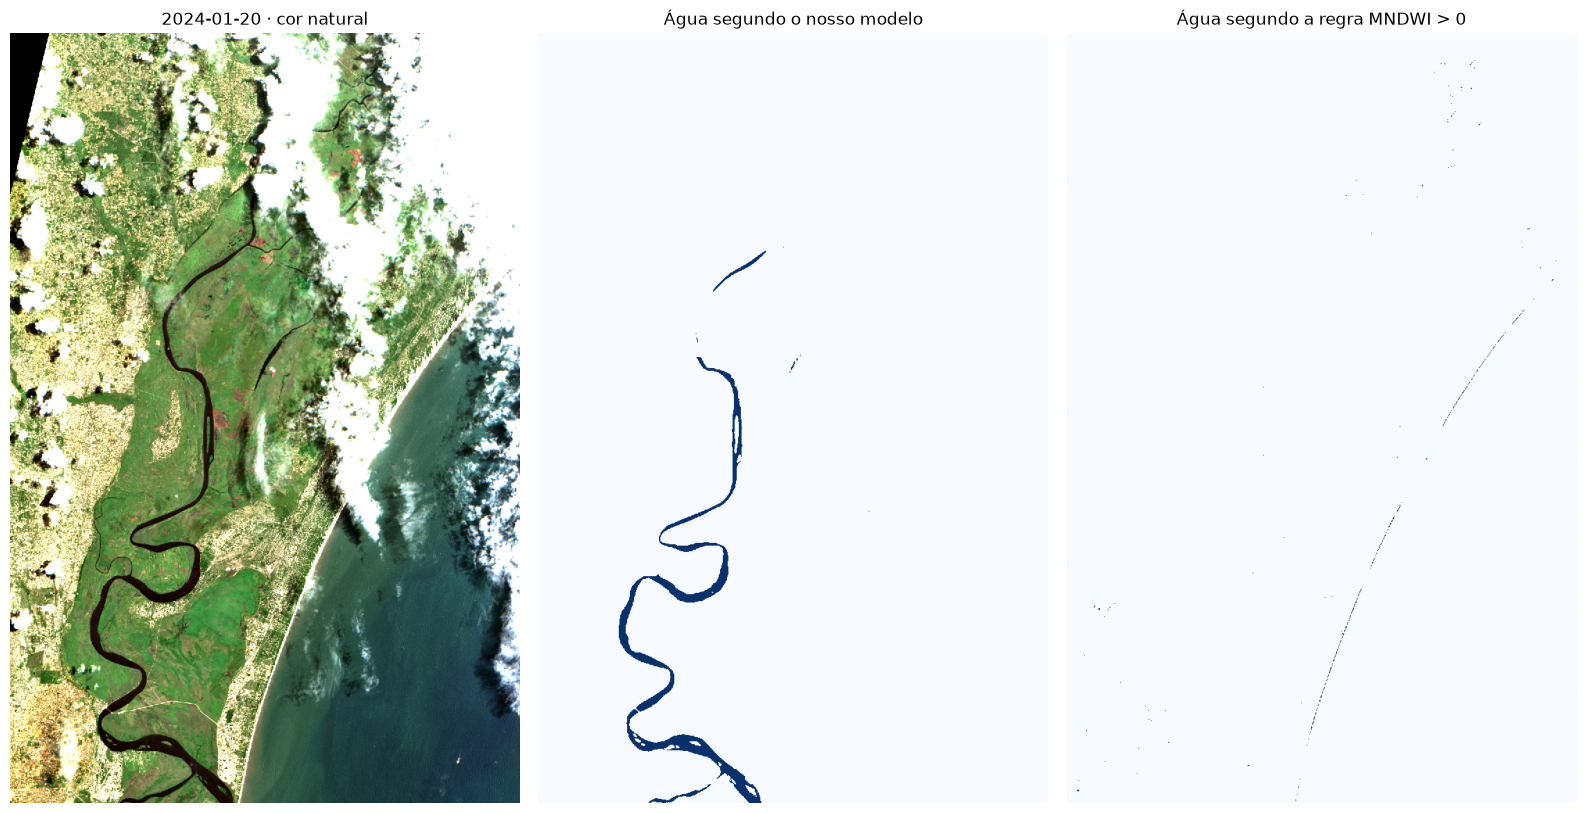

Os quatro algoritmos da Parte C (treinados só com 2026), no ano 2024:
  Árvore de decisão            encontra  97.2% do rio certo | falsos alarmes em terra alta  0.0%


  k vizinhos (k = 5)           encontra  96.9% do rio certo | falsos alarmes em terra alta  0.0%


  Random Forest (100 árvores)  encontra  96.4% do rio certo | falsos alarmes em terra alta  0.0%


  Rede neuronal (16 + 16)      encontra   0.1% do rio certo | falsos alarmes em terra alta  0.0%


In [15]:
ANO = 2024                                    # ✏️ o ano do vosso par: 2014, 2021, 2022, 2024 ou 2025
outro = carregar(f"incomati_{ANO}_chuvosa.npz")
juntar_terreno(outro, extra)
print(outro["data"], outro["satelite"], f"caudal {outro['caudal_m3s']:.0f} m³/s")

rio_certo = extra["verif_agua"] & ~outro["nuvem"]
terra_alta = extra["verif_terra"] & ~outro["nuvem"]


def verificar_ano(prob, img):
    rio = 100 * (prob[rio_certo] > CONFIG["limiar"]).mean()
    terra = 100 * (prob[terra_alta] > CONFIG["limiar"]).mean()
    return rio, terra


p_outro = prever(modelo, outro, CARACTERISTICAS)
rio, terra = verificar_ano(p_outro, outro)
print(f"\nO nosso modelo:   encontra {rio:5.1f}% do rio certo | falsos alarmes em terra alta {terra:4.1f}%")
for nome in ["mndwi", "ndwi"]:
    print(f"Regra {nome.upper()} > 0:{'' if nome == 'mndwi' else ' '} encontra {100 * (outro[nome][rio_certo] > 0).mean():5.1f}% do rio certo"
          f" | falsos alarmes em terra alta {100 * (outro[nome][terra_alta] > 0).mean():4.1f}%")

fig, eixos = plt.subplots(1, 3, figsize=(16, 8))
eixos[0].imshow(cor_natural(outro))
eixos[0].set_title(f"{outro['data']} · cor natural")
eixos[1].imshow((p_outro > CONFIG["limiar"]) & outro["zona"] & ~outro["nuvem"], cmap="Blues")
eixos[1].set_title("Água segundo o nosso modelo")
eixos[2].imshow((outro["mndwi"] > 0) & outro["zona"] & ~outro["nuvem"], cmap="Blues")
eixos[2].set_title("Água segundo a regra MNDWI > 0")
for e in eixos:
    e.axis("off")
plt.tight_layout()
plt.show()

print(f"Os quatro algoritmos da Parte C (treinados só com 2026), no ano {ANO}:")
for nome, m in ALGORITMOS.items():
    rio_m, terra_m = verificar_ano(prever(m, outro, CARACTERISTICAS), outro)
    print(f"  {nome:28s} encontra {rio_m:5.1f}% do rio certo | falsos alarmes em terra alta {terra_m:4.1f}%")

⏱️ **Tempo:** Parte D entre as 12:30 e as 12:45.

🔎 **Interpretação (modelo da equipa, só treinado com 2026).**

| Ano | Satélite | Modelo antes | Modelo depois de ensinar | Regra MNDWI | Regra NDWI | Nuvens |
| --- | --- | --- | --- | --- | --- | --- |
| 2014 | Landsat 8 | 95% | 95% | 98% | 93% | 0% |
| 2021 | Sentinel-2 | 46% | 89% | 77% | 51% | 40% |
| 2022 | Sentinel-2 | 93% | 95% | 66% | 93% | 15% |
| 2024 | Sentinel-2 | 96% | 97% | 0% | 91% | 20% |
| 2025 | Sentinel-2 | 86% | 89% | 92% | 91% | 25% |

(percentagem do **rio certo** que cada método encontra; os falsos alarmes em terra alta ficam perto de 0% em todos.)

- **2024:** o modelo encontra quase todo o rio; a regra MNDWI **0%** (água demasiado escura). O modelo ganha porque combina várias pistas.
- **2021:** o modelo **falha** (água barrenta, que nunca viu) e fica abaixo da regra MNDWI. Depois de 5 + 5 pontos, passa a regra.
- **2022:** o modelo empata com o NDWI e bate o MNDWI.
- **2014:** imagem de **outro satélite** (Landsat 8): o modelo treinado com Sentinel-2 funciona na mesma.
- **2025:** um pouco abaixo das regras (25% de nuvens); depois de ensinar, aproxima-se delas.

**Os quatro algoritmos no ano do par:** em 2021 todos falham (entre 46% e
58% do rio); em 2024 a árvore, os k vizinhos e o Random Forest encontram mais de 96% do rio,
mas a **rede neuronal encontra 0,1%**. Para os Pares 1 (2024) e 2 (2021) é a melhor conversa da prática.

### Passo D2 · Ensinar o modelo com exemplos desse ano ✏️

Se o modelo falhou, é porque **nunca viu** água assim. A solução do Machine Learning é simples: **mostrar-lhe
exemplos**. Marquem pelo menos **5 pontos de água** (no rio) e **5 de não água** (terra junto ao rio) nesse ano.
Usem a lupa: `ver_zona(outro, linha, coluna)`.

Ainda sem pontos vossos: uso os 5 + 5 da equipa para este ano.


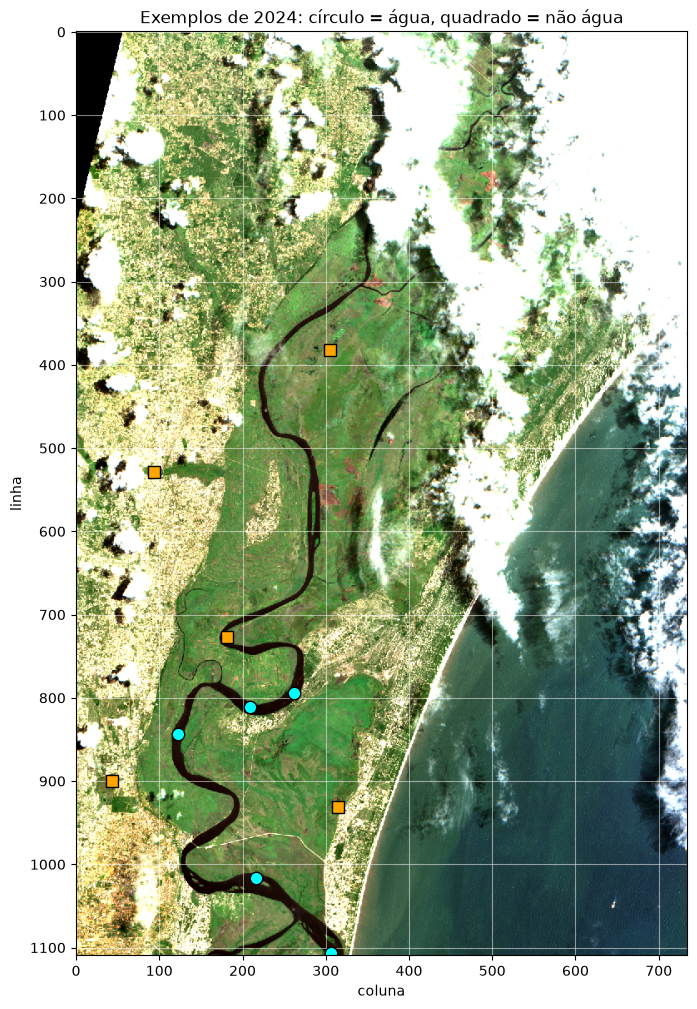

In [16]:
USAR_PONTOS_DA_EQUIPA_ANO = False            # ✏️ True para usar os 5 + 5 pontos da equipa para este ano

AGUA_ANO = []                                # ✏️ pontos de água neste ano, por exemplo (1017, 216)
NAO_AGUA_ANO = []                            # ✏️ pontos de não água neste ano

if USAR_PONTOS_DA_EQUIPA_ANO or min(len(AGUA_ANO), len(NAO_AGUA_ANO)) == 0:
    equipa = json.load(open(encontrar("exemplos_da_equipa.json")))
    if not USAR_PONTOS_DA_EQUIPA_ANO:
        print("Ainda sem pontos vossos: uso os 5 + 5 da equipa para este ano.")
    AGUA_ANO = [tuple(p) for p in equipa[str(ANO)]["agua"]]
    NAO_AGUA_ANO = [tuple(p) for p in equipa[str(ANO)]["nao_agua"]]
ver_imagem(outro, f"Exemplos de {ANO}: círculo = água, quadrado = não água", AGUA_ANO, NAO_AGUA_ANO)

In [17]:
X_ano, y_ano = exemplos(outro, AGUA_ANO, NAO_AGUA_ANO, CARACTERISTICAS, raio=CONFIG["raio_do_ponto"])
modelo2 = RandomForestClassifier(**modelo.get_params())                     # as mesmas configurações da Parte C
modelo2.fit(np.concatenate([X, X_ano]), np.concatenate([y, y_ano]))           # 2026 + o novo ano

rio2, terra2 = verificar_ano(prever(modelo2, outro, CARACTERISTICAS), outro)
p26 = prever(modelo2, cheia, CARACTERISTICAS)
r2 = notas(verdade, (p26[teste] > CONFIG["limiar"]).astype(int))
print(f"{ANO} · antes de ensinar: rio {rio:5.1f}% | terra alta {terra:4.1f}%")
print(f"{ANO} · depois de ensinar: rio {rio2:5.1f}% | terra alta {terra2:4.1f}%")
print(f"E em 2026 (exame EMS), o modelo novo ficou com IoU {r2['IoU']:.3f} (antes {notas(verdade, previsto)['IoU']:.3f})")
print(f"\nQUADRO DA TURMA -> ano {ANO} | rio antes {rio:.0f}% | rio depois {rio2:.0f}% | terra alta depois {terra2:.1f}%")

2024 · antes de ensinar: rio  96.4% | terra alta  0.0%
2024 · depois de ensinar: rio  97.3% | terra alta  0.0%
E em 2026 (exame EMS), o modelo novo ficou com IoU 0.964 (antes 0.962)

QUADRO DA TURMA -> ano 2024 | rio antes 96% | rio depois 97% | terra alta depois 0.0%


🔎 **Interpretação.** Ensinar 10 pontos de um ano difícil melhora esse ano (sobretudo em 2021) e **não estraga** 2026. IoU no exame EMS de
2026 depois de ensinar cada ano (antes: 0,962): 2014: 0,958; 2021: 0,985; 2022: 0,965; 2024: 0,964; 2025: 0,966. Ensinar 2021 até **melhora** 2026: a água barrenta de 2021 mostrou ao
modelo mais um tipo de água. É o ciclo real do Machine Learning: testar, encontrar onde falha, juntar exemplos desses casos, treinar outra vez.

🗣️ **Resposta-modelo:** a IA é tão boa quanto os exemplos que lhe damos; casos novos precisam de exemplos novos.

✍️ **Perguntas:** o modelo melhorou? Ficou pior em 2026? O que isto nos ensina sobre **os exemplos** que se dão
a uma IA? E o vencedor da Parte C ganhou também no vosso ano?

**Resposta-modelo:** Melhorou no ano ensinado (em 2021, de 46% para 89% do rio) e não piorou em 2026. Lição: a IA é tão boa quanto a variedade dos exemplos. O vencedor da Parte C nem sempre ganha no outro ano: em 2024 a rede neuronal falha.

---
## O que aprendemos

1. Na **aprendizagem supervisionada**, o modelo aprende com **exemplos com rótulos**: a qualidade e a variedade
   dos exemplos decidem tudo.
2. A nota nos próprios exemplos **engana**: testa-se com dados que o modelo nunca viu e rótulos independentes.
3. A **matriz de confusão** mostra os quatro resultados: água certa, terra certa, falso alarme e água perdida.
4. Algoritmos diferentes empatam numa imagem fácil, mas **não generalizam da mesma maneira**: o melhor no exame
   de 2026 pode falhar noutro ano.
5. Um modelo só sabe o que viu: quando falha, **ensinamos-lhe** exemplos desses casos.

**Próximo:** `3_sem_rotulos_e_numeros.ipynb`: agrupar píxeis **sem rótulos** (K-means) e **prever um número**
(o caudal do rio daqui a 3 dias).

## Se aparecer um erro

Leia **a última linha** da mensagem vermelha. Quase sempre é um destes:

| Última linha do erro | O que quer dizer | O que fazer |
| --- | --- | --- |
| `NameError: name 'np' is not defined` | Saltou a Célula 0 | Corra a Célula 0 e depois as outras, por ordem |
| `NameError: name 'cheia' is not defined` | Saltou a célula que carrega os dados | Corra as células por ordem, de cima para baixo |
| `FileNotFoundError: Não encontrei ...` | O Jupyter não foi aberto na pasta da prática | Abra o notebook a partir da pasta `Workshop_2/2_pratica` (os dados estão em `2_pratica/dados`) |
| `ModuleNotFoundError: No module named 'sklearn'` | Falta uma biblioteca neste computador | Chame o Facilitador 6 (`pip install scikit-learn`) |
| `ValueError: need at least one array to concatenate` | Não há pontos, ou caíram todos em nuvens | Marque pontos fora das nuvens, ou use os pontos da equipa |
| `SyntaxError` | Falta um parêntese, uma aspa ou uma vírgula | Compare a sua linha com o exemplo logo acima |
| `IndentationError` | Os espaços no início da linha estão errados | Use 4 espaços dentro de `if`, `for` e `def` |
| *Kernel died* / *Dead kernel* | O Python parou (memória ou erro grave) | Menu **Kernel → Restart Kernel** e corra outra vez por ordem |

Se nada resultar: menu **Kernel → Restart Kernel and Run All Cells** (nas versões antigas do Jupyter:
**Kernel → Restart & Run All**). O trabalho fica guardado no próprio computador: **Ctrl + S** para guardar.